Running Physics Sanity Check for Glioblastoma...


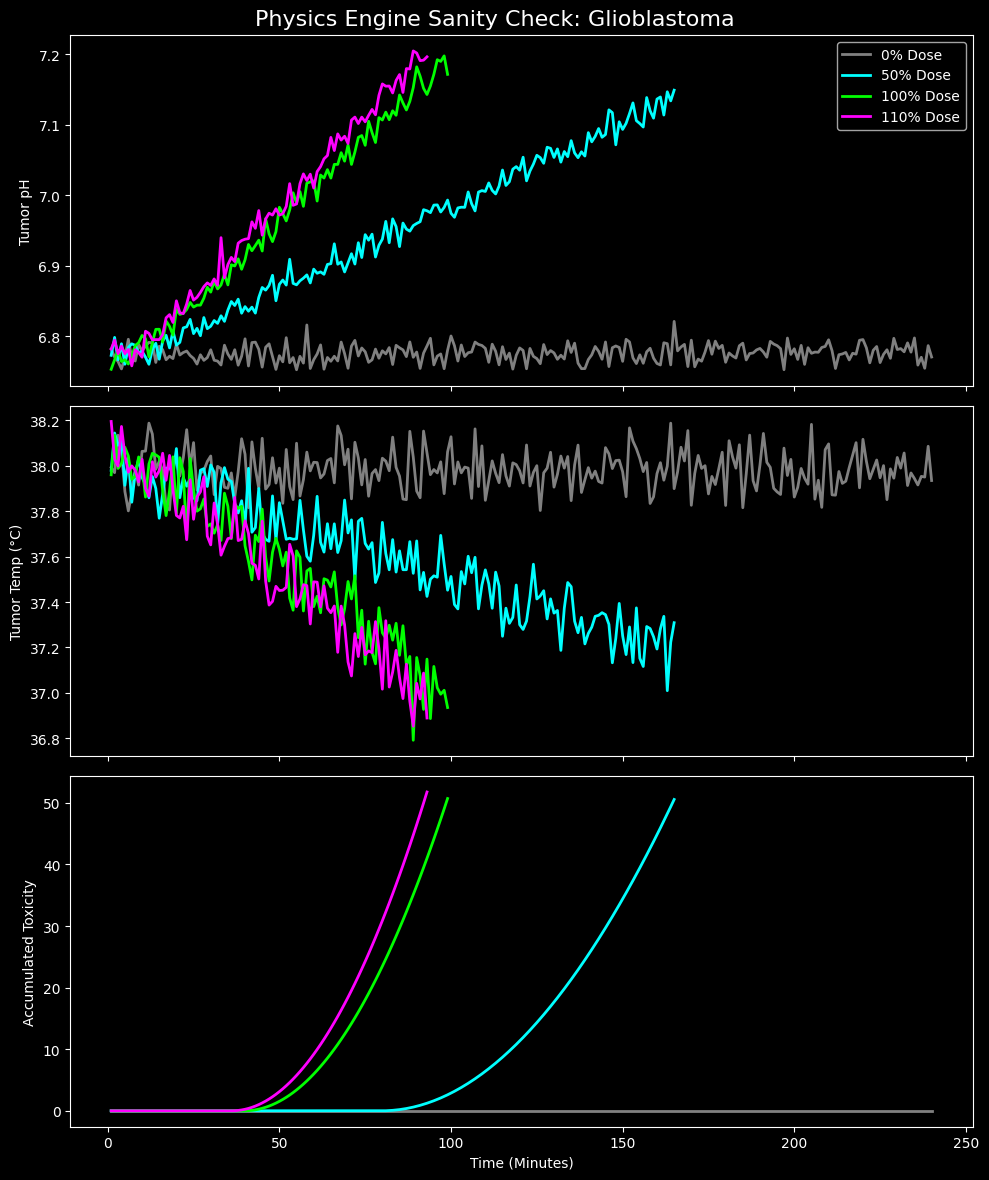

In [1]:
import matplotlib.pyplot as plt
from environment import PredictiveChemoEnv
from train import CANCER_PROFILES

def run_static_policy(env, dose_action):
    env.reset()
    history = {'time': [], 'ph': [], 'temp': [], 'tox': []}
    tz_idx = env.tumor_zone - 1
    
    terminated = False
    truncated = False
    
    while not (terminated or truncated):
        obs, reward, terminated, truncated, info = env.step(dose_action)
        history['time'].append(env.current_step)
        history['ph'].append(info['real_ph'])
        history['temp'].append(info['real_temp'])
        # Multiply by threshold to un-normalize toxicity for the plot
        history['tox'].append(obs[2] * env.critical_toxicity_threshold) 
        
    return history

def run_physics_sanity_check(cancer_name="Glioblastoma"):
    print(f"Running Physics Sanity Check for {cancer_name}...")
    
    data_path = "datasets/1_week_sampling_schedule.parquet"
    env = PredictiveChemoEnv(
        schedule_parquet_path=data_path, 
        drug_name=CANCER_PROFILES[cancer_name]['drug'], 
        tumor_zone=CANCER_PROFILES[cancer_name]['zone']
    )
    
    # Action map: 0=0%, 2=50%, 7=100%, 9=110%
    policies = {
        "0% Dose": 0, 
        "50% Dose": 2, 
        "100% Dose": 7, 
        "110% Dose": 9
    }
    
    results = {}
    for name, action in policies.items():
        results[name] = run_static_policy(env, action)
        
    # Plotting
    plt.style.use('dark_background')
    fig, axs = plt.subplots(3, 1, figsize=(10, 12), sharex=True)
    fig.suptitle(f'Physics Engine Sanity Check: {cancer_name}', fontsize=16)
    
    colors = ['gray', 'cyan', 'lime', 'magenta']
    
    for (name, history), color in zip(results.items(), colors):
        axs[0].plot(history['time'], history['ph'], label=name, color=color, linewidth=2)
        axs[1].plot(history['time'], history['temp'], label=name, color=color, linewidth=2)
        axs[2].plot(history['time'], history['tox'], label=name, color=color, linewidth=2)
        
    axs[0].set_ylabel('Tumor pH')
    axs[0].legend()
    axs[1].set_ylabel('Tumor Temp (°C)')
    axs[2].set_ylabel('Accumulated Toxicity')
    axs[2].set_xlabel('Time (Minutes)')
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    run_physics_sanity_check()

In [1]:
import numpy as np
from environment import PredictiveChemoEnv
from train import CANCER_PROFILES

def run_action_reward_test(cancer_name="Glioblastoma"):
    print(f"🚀 Running Pre-Flight Diagnostics: {cancer_name}...")
    
    env = PredictiveChemoEnv(
        schedule_parquet_path="datasets/1_week_sampling_schedule.parquet", 
        drug_name=CANCER_PROFILES[cancer_name]['drug'], 
        tumor_zone=CANCER_PROFILES[cancer_name]['zone']
    )
    
    action_rewards = {i: [] for i in range(10)}
    survival_times = []
    
    # Run 10 episodes with a completely random agent
    for ep in range(10):
        env.reset()
        terminated = False
        truncated = False
        
        while not (terminated or truncated):
            action = env.action_space.sample()  # Pure random exploration
            _, reward, terminated, truncated, _ = env.step(action)
            action_rewards[action].append(reward)
            
        survival_times.append(env.current_step)
        
    print("\n" + "="*50)
    print(" 📊 PRE-FLIGHT REWARD DISTRIBUTION")
    print("="*50)
    print(f"Average Random Survival Time: {np.mean(survival_times):.1f} / 240 mins\n")
    
    print(f"{'Action Tier':<15} | {'Times Chosen':<15} | {'Avg Immediate Reward'}")
    print("-" * 55)
    
    for act, mapped_dose in env.action_mapping.items():
        rewards = action_rewards[act]
        count = len(rewards)
        avg_rew = np.mean(rewards) if count > 0 else 0.0
        print(f"Tier {act} ({mapped_dose*100:>3.0f}%)  | {count:<15d} | {avg_rew:>10.4f}")
    
    print("\n[CHECK]: Are the high-dose rewards relatively balanced with the low-dose rewards now?")

if __name__ == "__main__":
    run_action_reward_test()

🚀 Running Pre-Flight Diagnostics: Glioblastoma...
    -> [CLINICAL ALERT] Minute 4: Massive emergency dose reduction (-105%)!
    -> [CLINICAL ALERT] Minute 12: Massive emergency dose reduction (-50%)!
    -> [CLINICAL ALERT] Minute 16: Massive emergency dose reduction (-65%)!
    -> [CLINICAL ALERT] Minute 31: Massive emergency dose reduction (-50%)!
    -> [CLINICAL ALERT] Minute 35: Massive emergency dose reduction (-70%)!
    -> [CLINICAL ALERT] Minute 41: Massive emergency dose reduction (-90%)!
    -> [CLINICAL ALERT] Minute 44: Massive emergency dose reduction (-50%)!
    -> [CLINICAL ALERT] Minute 49: Massive emergency dose reduction (-75%)!
    -> [CLINICAL ALERT] Minute 58: Massive emergency dose reduction (-90%)!
    -> [CLINICAL ALERT] Minute 63: Massive emergency dose reduction (-55%)!
    -> [CLINICAL ALERT] Minute 72: Massive emergency dose reduction (-60%)!
    -> [CLINICAL ALERT] Minute 78: Massive emergency dose reduction (-50%)!
    -> [CLINICAL ALERT] Minute 80: Mas